# HW2 — YOLO11s Final Pipeline (Kaggle, 1536 px)

**Ціль:** сильний, відтворюваний YOLO11s pipeline з обережним збільшенням кількості GroupKFold моделей та повним збереженням артефактів.

- Одна конфігурація: YOLO11s, 1536 px, 14 epochs, `box=7.5`, `mosaic=1.0`.
- 5 GroupKFold folds: кожна модель навчається на 80% груп (відео), ensemble містить до 5 моделей.
- OOF оцінювання на повному held-out fold; ніякого поділу кадрів одного відео між train/validation.
- Зберігаємо `best.pt`, `last.pt`, метрики та OOF predictions після кожного fold.
- Test inference + WBF, CSV validation та ZIP резервної копії ваг.

**Чесне застереження:** жоден ноутбук не може гарантувати приріст Public Score на 0.03. П'ять folds можуть дати сильніший ensemble завдяки більшій частці train-даних на кожну модель, але це гіпотеза, яку треба перевірити на OOF. 5 folds також дорожчі за 3.

In [1]:
# 1. Залежності та імпорти
!pip -q install ultralytics==8.4.201 pycocotools ensemble-boxes

import os, json, time, gc, math, random, shutil, contextlib, io
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from PIL import Image

from sklearn.model_selection import GroupKFold
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from ultralytics import YOLO, settings

settings.update({"wandb": False})
assert torch.cuda.is_available(), "Увімкни GPU у Settings → Accelerator."
print("Ultralytics:", __import__("ultralytics").__version__)
print("GPU:", torch.cuda.get_device_name(0))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics: 8.4.201
GPU: Tesla T4


In [2]:
# 2. Знайти датасет, доданий через Kaggle Add Input
INPUT_ROOT = Path("/kaggle/input")
hits = []
for p in INPUT_ROOT.rglob("annotations_coco.json"):
    if p.parent.name in ("train", "val"):
        root = p.parent.parent
        if ((root / "train" / "annotations_coco.json").exists()
            and (root / "val" / "annotations_coco.json").exists()
            and (root / "test_images.csv").exists()):
            hits.append(root)

if not hits:
    print("Доступні inputs:")
    for p in INPUT_ROOT.iterdir():
        print(" -", p)
    raise FileNotFoundError(
        "Не знайдено train/annotations_coco.json, val/annotations_coco.json і test_images.csv. "
        "Додай competition dataset через Add Input."
    )

DATA = hits[0]
print("Dataset:", DATA)
print("Test metadata:", DATA / "test_images.csv")

Dataset: /kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026
Test metadata: /kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026/test_images.csv


In [3]:
# 3. Конфігурація фінального експерименту
SEED = 42
STEP = 4
N_FOLDS = 5
RUN_FOLDS = list(range(N_FOLDS))

IMGSZ = 1536
EPOCHS = 12
PATIENCE = 6
BATCH = 2
WORKERS = 2
SAVE_MAX = 1600
INNER_VAL = 500

MAX_DET = 500
VAL_CONF = 0.001
NMS_IOU = 0.6
CLASSES = ["person", "bicycle", "car", "van", "truck", "tricycle", "bus", "motor"]

MODEL_WEIGHTS = "yolo11s.pt"
EXPERIMENTS = {
    "Y11s_1536_5fold_final": {"box": 7.5, "mosaic": 1.0},
}

OUT = Path("/kaggle/working")
WORK = OUT / "yolo11_final_data"
RUNS = OUT / "yolo11_final_runs"
WEIGHTS_OUT = OUT / "yolo11_final_weights"
RESULTS = OUT / "yolo11_final_results"
OOF_OUT = OUT / "yolo11_final_oof"
for d in (WORK, RUNS, WEIGHTS_OUT, RESULTS, OOF_OUT):
    d.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Image size:", IMGSZ, "| epochs:", EPOCHS, "| batch:", BATCH, "| folds:", RUN_FOLDS)
print("Experiment grid:", EXPERIMENTS)

Image size: 1536 | epochs: 12 | batch: 2 | folds: [0, 1, 2, 3, 4]
Experiment grid: {'Y11s_1536_5fold_final': {'box': 7.5, 'mosaic': 1.0}}


## 1. Протокол даних і фолди

Об'єднуємо train/val метадані, але розбиваємо за `video` через `GroupKFold`: кадри одного кліпу не потрапляють одночасно в train і OOF validation. Беремо кожен 4-й кадр, як у початковому pipeline. `iscrowd=1` регіони виключаються з оцінки та маскуються на зображеннях.

In [4]:
# 4. Прочитати COCO annotations і створити GroupKFold
OFF = {"train": 0, "val": 10**7}

def load_split(split):
    with open(DATA / split / "annotations_coco.json", "r") as f:
        coco = json.load(f)

    imgs = pd.DataFrame(coco["images"]).rename(columns={"id": "image_id"})
    imgs["path"] = [
        str(DATA / split / "images" / str(v) / Path(fname).name)
        for v, fname in zip(imgs["video"], imgs["file_name"])
    ]
    imgs["split"] = split
    imgs["image_id"] = imgs["image_id"] + OFF[split]

    ann = pd.DataFrame(coco["annotations"]).copy()
    ann["image_id"] = ann["image_id"] + OFF[split]
    ann[["x", "y", "w", "h"]] = pd.DataFrame(ann["bbox"].tolist(), index=ann.index)
    ann["cls"] = ann["category_id"] - 1
    ann = ann.merge(
        imgs[["image_id", "video", "frame_id", "width", "height"]],
        on="image_id"
    )
    target = ann[ann["iscrowd"] == 0].drop(columns=["bbox"]).reset_index(drop=True)
    ignored = ann[ann["iscrowd"] == 1].drop(columns=["bbox"]).reset_index(drop=True)
    return imgs, target, ignored

T = {s: load_split(s) for s in OFF}
imgs_all = pd.concat([T[s][0] for s in OFF], ignore_index=True)
obj_all = pd.concat([T[s][1] for s in OFF], ignore_index=True)
ign_all = pd.concat([T[s][2] for s in OFF], ignore_index=True)

assert not (set(T["train"][0].video) & set(T["val"][0].video)), "Train/val video clips overlap!"

OBJ_BY_IMG = {k: g for k, g in obj_all.groupby("image_id")}
IGN_BY_IMG = {k: g[["x", "y", "w", "h"]].values for k, g in ign_all.groupby("image_id")}

fold_of = {}
for k, (_, te) in enumerate(
    GroupKFold(n_splits=N_FOLDS).split(imgs_all, groups=imgs_all.video)
):
    fold_of.update({v: k for v in imgs_all.video.iloc[te].unique()})

FR = imgs_all.sort_values(["video", "frame_id"]).copy()
FR = FR[FR.groupby("video").cumcount() % STEP == 0].copy()
FR["fold"] = FR.video.map(fold_of)
FR = FR.reset_index(drop=True)

TRAIN = lambda k: FR[FR.fold != k]
VAL = lambda k: FR[FR.fold == k]
VSUB = lambda k: VAL(k).sample(min(INNER_VAL, len(VAL(k))), random_state=SEED)

print(FR.groupby("fold").agg(clips=("video", "nunique"), frames=("image_id", "size")))
print("Total sampled frames:", len(FR))

      clips  frames
fold               
0        12    1354
1        13    1366
2        12    1348
3        13    1360
4        13    1358
Total sampled frames: 6786


In [5]:
# 5. Підготувати зображення та YOLO labels
def prep_all(root):
    root = Path(root)

    def one(r):
        img_path = root / "images" / r.video / Path(r.path).name
        label_path = root / "labels" / r.video / (img_path.stem + ".txt")

        if img_path.exists() and label_path.exists():
            return

        img_path.parent.mkdir(parents=True, exist_ok=True)
        label_path.parent.mkdir(parents=True, exist_ok=True)

        g = OBJ_BY_IMG.get(r.image_id)
        labels = []
        if g is not None and len(g):
            b = np.clip(
                np.c_[g.x, g.y, g.x + g.w, g.y + g.h],
                0, [r.width, r.height] * 2
            )
            valid = (b[:, 2] > b[:, 0]) & (b[:, 3] > b[:, 1])
            labels = [
                f"{int(c)} {(x1+x2)/2/r.width:.6f} {(y1+y2)/2/r.height:.6f} "
                f"{(x2-x1)/r.width:.6f} {(y2-y1)/r.height:.6f}"
                for c, (x1, y1, x2, y2) in zip(g.cls.values[valid], b[valid])
            ]
        label_path.write_text("\n".join(labels))

        im = Image.open(r.path).convert("RGB")
        arr = np.array(im)
        for x, y, w, h in IGN_BY_IMG.get(r.image_id, []):
            x1 = max(0, int(x)); y1 = max(0, int(y))
            x2 = min(arr.shape[1], int(np.ceil(x + w)))
            y2 = min(arr.shape[0], int(np.ceil(y + h)))
            if x2 > x1 and y2 > y1:
                arr[y1:y2, x1:x2] = 114
        im = Image.fromarray(arr)
        im.thumbnail((SAVE_MAX, SAVE_MAX))
        im.save(img_path, quality=95)

    with ThreadPoolExecutor(max_workers=8) as ex:
        list(ex.map(one, list(FR.itertuples(index=False))))
    print("Prepared", len(FR), "frames in", root)

def fold_yaml(k):
    for name, df in [("train", TRAIN(k)), ("val", VSUB(k))]:
        (WORK / f"fold{k}_{name}.txt").write_text("\n".join(
            str(WORK / "images" / r.video / Path(r.path).name)
            for r in df.itertuples(index=False)
        ))

    y = WORK / f"data_fold{k}.yaml"
    y.write_text(
        f"path: {WORK}\n"
        f"train: {WORK / f'fold{k}_train.txt'}\n"
        f"val: {WORK / f'fold{k}_val.txt'}\n"
        f"names: {dict(enumerate(CLASSES))}\n"
    )
    return y

prep_all(WORK)

Prepared 6786 frames in /kaggle/working/yolo11_final_data


In [6]:
# 6. COCO OOF evaluation: mAP та AP за розміром об'єкта
_GT = None

def get_gt():
    global _GT
    if _GT is None:
        o = obj_all[obj_all.image_id.isin(FR.image_id)]
        dataset = {
            "images": [
                {"id": int(i), "width": int(w), "height": int(h)}
                for i, w, h in zip(FR.image_id, FR.width, FR.height)
            ],
            "annotations": [
                {
                    "id": n + 1, "image_id": int(i), "category_id": int(c) + 1,
                    "bbox": [float(x), float(y), float(w), float(h)],
                    "area": float(w * h), "iscrowd": 0
                }
                for n, (i, c, x, y, w, h) in enumerate(
                    zip(o.image_id, o.cls, o.x, o.y, o.w, o.h)
                )
            ],
            "categories": [
                {"id": i + 1, "name": name} for i, name in enumerate(CLASSES)
            ]
        }
        cg = COCO()
        cg.dataset = dataset
        with contextlib.redirect_stdout(io.StringIO()):
            cg.createIndex()
        _GT = cg
    return _GT

def drop_ignored(xyxy, scores, labels, ign, thr=0.5):
    if len(xyxy) == 0 or len(ign) == 0:
        return xyxy, scores, labels
    gx1, gy1 = ign[:, 0], ign[:, 1]
    gx2, gy2 = ign[:, 0] + ign[:, 2], ign[:, 1] + ign[:, 3]
    ix = (np.minimum(xyxy[:, None, 2], gx2) - np.maximum(xyxy[:, None, 0], gx1)).clip(0)
    iy = (np.minimum(xyxy[:, None, 3], gy2) - np.maximum(xyxy[:, None, 1], gy1)).clip(0)
    area = ((xyxy[:, 2] - xyxy[:, 0]) * (xyxy[:, 3] - xyxy[:, 1])).clip(1e-6)
    keep = (ix * iy).sum(1) / area < thr
    return xyxy[keep], scores[keep], labels[keep]

def coco_eval(preds, frame_df, ms_per_img=float("nan")):
    rows = []
    for iid, path in zip(frame_df.image_id, frame_df.path):
        xyxy, scores, labels = preds[str(Path(path))]
        xyxy, scores, labels = drop_ignored(
            xyxy, scores, labels, IGN_BY_IMG.get(iid, np.zeros((0, 4)))
        )
        if len(scores):
            rows.append(np.c_[
                np.full(len(scores), iid),
                xyxy[:, 0], xyxy[:, 1],
                xyxy[:, 2] - xyxy[:, 0], xyxy[:, 3] - xyxy[:, 1],
                scores, labels + 1
            ])

    dets = np.concatenate(rows).astype(np.float64) if rows else np.zeros((0, 7))
    gt = get_gt()
    with contextlib.redirect_stdout(io.StringIO()):
        if len(dets):
            dt = gt.loadRes(dets)
        else:
            dt = COCO()
            dt.dataset = {
                "images": gt.dataset["images"],
                "categories": gt.dataset["categories"],
                "annotations": []
            }
            dt.createIndex()

        ev = COCOeval(gt, dt, "bbox")
        ev.params.imgIds = [int(i) for i in frame_df.image_id]
        ev.params.maxDets = [1, 10, MAX_DET]
        ev.evaluate(); ev.accumulate(); ev.summarize()

    P = ev.eval["precision"]
    def ap(area=0, iou=None):
        p = P[:, :, :, area, 2] if iou is None else P[
            [int(np.argmin(abs(ev.params.iouThrs - iou)))], :, :, area, 2
        ]
        return float(p[p > -1].mean()) if (p > -1).any() else float("nan")

    return {
        "mAP": ap(), "AP50": ap(iou=0.5),
        "AP_small": ap(1), "AP_medium": ap(2), "AP_large": ap(3),
        "ms_per_img": float(ms_per_img)
    }

def predict_fn(model, paths, imgsz=IMGSZ, conf=VAL_CONF, batch=4):
    out, total_ms = {}, 0.0
    for start in range(0, len(paths), batch):
        results = model.predict(
            paths[start:start + batch],
            imgsz=imgsz, conf=conf, iou=NMS_IOU,
            max_det=MAX_DET, device=0, verbose=False
        )
        for r in results:
            b = r.boxes
            out[str(Path(r.path))] = (
                b.xyxy.cpu().numpy(),
                b.conf.cpu().numpy(),
                b.cls.cpu().numpy().astype(int)
            )
            total_ms += sum(r.speed.values())
    return out, total_ms / max(len(paths), 1)

def evaluate_model(model, frame_df):
    preds, ms = predict_fn(model, [str(p) for p in frame_df.path])
    metrics = coco_eval(preds, frame_df, ms)
    del preds
    gc.collect()
    torch.cuda.empty_cache()
    return metrics

## Anchor-free YOLO11: location assignment

YOLO11 не використовує заздалегідь задані anchor boxes. Detection head прогнозує класи та координати від точок feature maps на кількох рівнях піраміди ознак. Task-Aligned Assigner вибирає позитивні позиції за узгодженістю classification score та IoU і розв'язує конфлікти між GT.

- Для малих об'єктів вища роздільність дає більше пікселів і може полегшити локалізацію.
- У щільних сценах близькі GT можуть конкурувати за позитивні позиції.
- Збільшення кількості folds не змінює assigner, але кожна модель бачить більшу частку навчальних відео (80% при 5 folds проти 66.7% при 3 folds).

`box=7.5` збережено як перевірену initial конфігурацію: попередній експеримент 1536 показав кращий середній mAP для initial, ніж для одночасно змінених `box=10` і `mosaic=0.7`. Оскільки обидва параметри тоді змінювалися разом, їхні індивідуальні ефекти не можна відокремити.

In [7]:
# 7. Навчання 5 folds з відновленням, OOF predictions та резервним копіюванням
def metrics_file(exp, k):
    return RESULTS / f"{exp}_f{k}.json"

def weight_file(exp, k):
    return RUNS / f"{exp}_f{k}" / "weights" / "best.pt"

def checkpoint_fold(exp, k):
    wf = weight_file(exp, k)
    last = wf.parent / "last.pt"
    copied_best = WEIGHTS_OUT / f"{exp}_fold{k}_best.pt"
    copied_last = WEIGHTS_OUT / f"{exp}_fold{k}_last.pt"
    if wf.exists():
        shutil.copy2(wf, copied_best)
    if last.exists():
        shutil.copy2(last, copied_last)
    # ZIP оновлюється після кожного fold — скачай його з Output до завершення сесії.
    zip_base = OUT / "yolo11_final_checkpoint_backup"
    shutil.make_archive(str(zip_base), "zip", root_dir=WEIGHTS_OUT)
    print("Checkpoint backup updated:", str(zip_base) + ".zip")

def train_one(exp, k, cfg):
    mf = metrics_file(exp, k)
    wf = weight_file(exp, k)
    run_name = f"{exp}_f{k}"
    run_dir = RUNS / run_name
    last = run_dir / "weights" / "last.pt"
    oof_file = OOF_OUT / f"{exp}_f{k}_oof.npz"

    if mf.exists() and wf.exists() and oof_file.exists():
        print("Already completed:", run_name)
        checkpoint_fold(exp, k)
        return json.load(open(mf))["metrics"]

    data_yaml = fold_yaml(k)

    if not wf.exists():
        if last.exists():
            print("Found last.pt; resuming:", run_name)
            model = YOLO(str(last))
            model.train(resume=True)
        else:
            model = YOLO(MODEL_WEIGHTS)
            model.train(
                data=str(data_yaml),
                imgsz=IMGSZ,
                epochs=EPOCHS,
                batch=BATCH,
                device=0,
                workers=WORKERS,
                seed=SEED,
                optimizer="auto",
                box=cfg["box"],
                mosaic=cfg["mosaic"],
                close_mosaic=3,
                patience=PATIENCE,
                amp=True,
                plots=True,
                project=str(RUNS),
                name=run_name,
                exist_ok=True,
                cache=False,
                save=True,
                val=True
            )
        del model
        gc.collect()
        torch.cuda.empty_cache()

    if not wf.exists():
        raise FileNotFoundError(f"best.pt not found: {wf}")

    model = YOLO(str(wf))
    val_paths = [str(p) for p in VAL(k).path.tolist()]
    preds, ms = predict_fn(model, val_paths, imgsz=IMGSZ, conf=VAL_CONF, batch=2)
    metrics = coco_eval(preds, VAL(k), ms)

    # Ragged detections stored as flat arrays + offsets for later threshold/WBF experiments.
    image_ids, offsets, all_boxes, all_scores, all_labels = [], [0], [], [], []
    val_df = VAL(k).reset_index(drop=True)
    for r in val_df.itertuples(index=False):
        b, s, l = preds[str(Path(r.path))]
        image_ids.append(int(r.image_id))
        all_boxes.extend(b.tolist())
        all_scores.extend(s.tolist())
        all_labels.extend(l.tolist())
        offsets.append(len(all_boxes))
    np.savez_compressed(
        oof_file,
        image_ids=np.asarray(image_ids, dtype=np.int64),
        offsets=np.asarray(offsets, dtype=np.int64),
        boxes=np.asarray(all_boxes, dtype=np.float32).reshape(-1, 4),
        scores=np.asarray(all_scores, dtype=np.float32),
        labels=np.asarray(all_labels, dtype=np.int16),
        paths=np.asarray(val_df.path.astype(str).tolist())
    )
    del preds, model
    gc.collect()
    torch.cuda.empty_cache()

    checkpoint_fold(exp, k)
    payload = {
        "metrics": metrics,
        "cfg": {
            "model": MODEL_WEIGHTS, "imgsz": IMGSZ, "epochs": EPOCHS,
            "batch": BATCH, "fold": k, "seed": SEED, **cfg
        },
        "weights": str(WEIGHTS_OUT / f"{exp}_fold{k}_best.pt"),
        "oof_predictions": str(oof_file)
    }
    with open(mf, "w") as f:
        json.dump(payload, f, indent=2)

    print(run_name, {a: round(float(b), 4) for a, b in metrics.items()})
    return metrics

started = time.time()
all_metrics = {}
for exp, cfg in EXPERIMENTS.items():
    all_metrics[exp] = {}
    for k in RUN_FOLDS:
        all_metrics[exp][k] = train_one(exp, k, cfg)
        print(f"Elapsed so far: {(time.time() - started) / 3600:.2f} hours")
print("Training/evaluation loop finished.")

New https://pypi.org/project/ultralytics/8.4.208 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.201 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=2, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=3, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/yolo11_final_data/data_fold0.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=12, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1536, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=y

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/12      5.64G      1.572       1.01      1.149        211       1536: 100% ━━━━━━━━━━━━ 2716/2716 6.0it/s 7:34
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 125/125 10.2it/s 12.3s
                   all        500      26971       0.61      0.441      0.458      0.247

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/12      5.64G      1.534     0.9399       1.13        259       1536: 100% ━━━━━━━━━━━━ 2716/2716 6.0it/s 7:34
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 125/125 9.9it/s 12.6s
                   all        500      26971      0.522       0.45      0.428      0.226

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/12         6G        1.5     0.8913      1.116        192       1536: 100% ━━━━━━━━━━━━ 2716/2716 6.0it/s 7:33
                 Class     Images  Instance

In [8]:
# 8. Звести OOF-метрики та вибрати конфігурацію
rows = []
for exp in EXPERIMENTS:
    for k in RUN_FOLDS:
        f = metrics_file(exp, k)
        if f.exists():
            rows.append({"experiment": exp, "fold": k, **json.load(open(f))["metrics"]})

fold_table = pd.DataFrame(rows)
display(fold_table.round(4))

summary = (
    fold_table.groupby("experiment")[["mAP", "AP50", "AP_small", "AP_medium", "AP_large", "ms_per_img"]]
    .mean().round(4)
)
summary["mAP_std"] = fold_table.groupby("experiment")["mAP"].std().round(4)
display(summary.sort_values("mAP", ascending=False))

best_exp = summary["mAP"].idxmax()
print("Selected by mean OOF mAP:", best_exp)
summary.to_csv(OUT / "yolo11_final_oof_summary.csv")
fold_table.to_csv(OUT / "yolo11_final_oof_by_fold.csv", index=False)

,experiment,fold,mAP,AP50,AP_small,AP_medium,AP_large,ms_per_img
0,Y11s_1536_5fold_final,0,0.2321,0.4233,0.0733,0.1686,0.3613,44.5073
1,Y11s_1536_5fold_final,1,0.2345,0.4662,0.0705,0.2498,0.3340,44.5405
2,Y11s_1536_5fold_final,2,0.1975,0.3865,0.0821,0.2044,0.3710,45.3163
3,Y11s_1536_5fold_final,3,0.2287,0.4245,0.0721,0.2288,0.4440,43.9839
4,Y11s_1536_5fold_final,4,0.2187,0.4135,0.1015,0.2464,0.4016,44.3416


,mAP,AP50,AP_small,AP_medium,AP_large,ms_per_img,mAP_std
experiment,,,,,,,
Y11s_1536_5fold_final,0.2223,0.4228,0.0799,0.2196,0.3824,44.5379,0.0151


Selected by mean OOF mAP: Y11s_1536_5fold_final


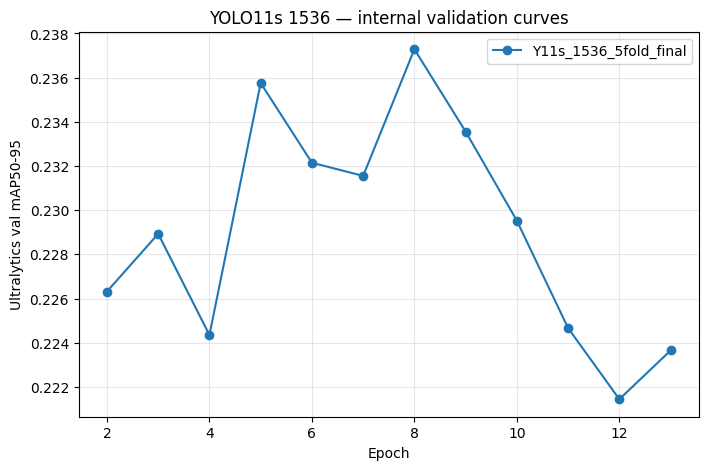

Training time per fold (hours):
Y11s_1536_5fold_final fold 0 1.54
Y11s_1536_5fold_final fold 1 0.91
Y11s_1536_5fold_final fold 2 1.55
Y11s_1536_5fold_final fold 3 1.55
Y11s_1536_5fold_final fold 4 1.55


In [9]:
# 9. Крива навчання та час для кожної конфігурації
fig, ax = plt.subplots(figsize=(8, 5))
for exp in EXPERIMENTS:
    dfs = []
    for k in RUN_FOLDS:
        f = RUNS / f"{exp}_f{k}" / "results.csv"
        if f.exists():
            d = pd.read_csv(f)
            d.columns = [x.strip() for x in d.columns]
            dfs.append(d)
    if dfs:
        curve = pd.concat(dfs).groupby("epoch").mean(numeric_only=True)
        if "metrics/mAP50-95(B)" in curve:
            ax.plot(curve.index + 1, curve["metrics/mAP50-95(B)"], marker="o", label=exp)
ax.set_xlabel("Epoch")
ax.set_ylabel("Ultralytics val mAP50-95")
ax.set_title("YOLO11s 1536 — internal validation curves")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

print("Training time per fold (hours):")
for exp in EXPERIMENTS:
    for k in RUN_FOLDS:
        f = RUNS / f"{exp}_f{k}" / "results.csv"
        if f.exists():
            d = pd.read_csv(f)
            d.columns = [x.strip() for x in d.columns]
            if "time" in d:
                print(exp, "fold", k, round(float(d.time.iloc[-1]) / 3600, 2))

## 3. Порівняння з anchor-based моделями

`AP_small`, `AP_medium`, `AP_large` у таблиці вище — основний розподіл за розміром об'єкта. Щоб заповнити порівняння з Faster R-CNN / RetinaNet із ноутбука №1, завантаж у Kaggle як окремий Input CSV `anchor_based_metrics.csv` з колонками:

`model,mAP,AP_small,AP_medium,AP_large`

Один рядок на кожен anchor-based експеримент. Не вигадуй значення: якщо файл не додано, клітинка нижче збере шаблон для заповнення. Порівнюй на однакових OOF-фолдах/метриці, якщо це можливо.

In [10]:
# 10. Звітна таблиця: фінальний YOLO + попередні anchor-based результати
yolo_report = summary.reset_index().rename(columns={"experiment": "model"})
template = pd.DataFrame([
    {"model": "Faster R-CNN tuned", "mAP": np.nan, "AP_small": np.nan, "AP_medium": np.nan, "AP_large": np.nan},
    {"model": "RetinaNet tuned", "mAP": np.nan, "AP_small": np.nan, "AP_medium": np.nan, "AP_large": np.nan},
    {"model": "RT-DETR", "mAP": 0.1354, "AP_small": 0.0554, "AP_medium": 0.1252, "AP_large": 0.2579},
])
anchor_files = list(Path("/kaggle/input").rglob("anchor_based_metrics.csv"))
if anchor_files:
    anchor = pd.read_csv(anchor_files[0])
    report = pd.concat([yolo_report, anchor], ignore_index=True, sort=False)
else:
    report = pd.concat([yolo_report, template], ignore_index=True, sort=False)
    print("Fill Faster R-CNN / RetinaNet rows from their actual validation results.")

cols = ["model", "mAP", "AP_small", "AP_medium", "AP_large"]
display(report[[c for c in cols if c in report.columns]].round(4))
report.to_csv(OUT / "final_detector_comparison.csv", index=False)

Fill Faster R-CNN / RetinaNet rows from their actual validation results.


,model,mAP,AP_small,AP_medium,AP_large
0,Y11s_1536_5fold_final,0.2223,0.0799,0.2196,0.3824
1,Faster R-CNN tuned,NaN,NaN,NaN,NaN
2,RetinaNet tuned,NaN,NaN,NaN,NaN
3,RT-DETR,0.1354,0.0554,0.1252,0.2579


In [11]:
!pip install -q ensemble-boxes

In [12]:
# 11. Test inference: усі доступні fold-моделі
from ensemble_boxes import weighted_boxes_fusion

test = pd.read_csv(DATA / "test_images.csv")
test_paths = [str(DATA / f) for f in test.file_name]
missing = [p for p in test_paths[:100] if not Path(p).exists()]
if missing:
    raise FileNotFoundError("Test image not found: " + missing[0])

best_exp = "Y11s_1536_5fold_final"
available_weights = [
    WEIGHTS_OUT / f"{best_exp}_fold{k}_best.pt"
    for k in RUN_FOLDS
]
available_weights = [p for p in available_weights if p.exists()]
if not available_weights:
    raise FileNotFoundError("No saved fold weights found in " + str(WEIGHTS_OUT))

print("Using", len(available_weights), "fold models")
fold_preds = []
for w in available_weights:
    model = YOLO(str(w))
    pred, _ = predict_fn(model, test_paths, imgsz=IMGSZ, conf=0.001, batch=2)
    fold_preds.append(pred)
    del model
    gc.collect()
    torch.cuda.empty_cache()

print("Test predictions collected from", len(fold_preds), "fold models.")

Using 5 fold models
Test predictions collected from 5 fold models.


In [13]:
# 12. WBF і submission CSV у форматі змагання
submission_rows = []
for row in test.itertuples(index=False):
    path = str(DATA / row.file_name)
    W, H = int(row.width), int(row.height)

    boxes_list, scores_list, labels_list = [], [], []
    for pred in fold_preds:
        xyxy, scores, labels = pred[path]
        if len(xyxy):
            boxes_list.append(np.clip(
                xyxy / np.array([W, H, W, H]), 0, 1
            ).tolist())
            scores_list.append(scores.tolist())
            labels_list.append(labels.tolist())
        else:
            boxes_list.append([])
            scores_list.append([])
            labels_list.append([])

    boxes, scores, labels = weighted_boxes_fusion(
        boxes_list, scores_list, labels_list,
        weights=[1.0] * len(fold_preds),
        iou_thr=0.6,
        skip_box_thr=0.001
    )

    # Kaggle обмежує кількість детекцій до 500 на зображення.
    if len(scores) > 500:
        keep = np.argsort(scores)[::-1][:500]
        boxes, scores, labels = boxes[keep], scores[keep], labels[keep]

    boxes = boxes * np.array([W, H, W, H])
    order = np.argsort(scores)[::-1]
    pred_string = " ".join(
        f"{int(labels[j])} {float(scores[j]):.4f} "
        f"{float(boxes[j,0]):.1f} {float(boxes[j,1]):.1f} "
        f"{float(boxes[j,2]-boxes[j,0]):.1f} "
        f"{float(boxes[j,3]-boxes[j,1]):.1f}"
        for j in order
    )
    submission_rows.append([row.image_id, pred_string])

submission = pd.DataFrame(submission_rows, columns=["image_id", "PredictionString"])
submission_path = OUT / f"submission_{best_exp}_folds_wbf.csv"
submission.to_csv(submission_path, index=False)
print("Saved:", submission_path)
display(submission.head())

/usr/local/lib/python3.13/dist-packages/ensemble_boxes/ensemble_boxes_wbf.py:66: UserWarning: Zero area box skipped: [0.0, 0.0, 0.005410817265510559, 0.0].
  warnings.warn("Zero area box skipped: {}.".format(box_part))
/usr/local/lib/python3.13/dist-packages/ensemble_boxes/ensemble_boxes_wbf.py:66: UserWarning: Zero area box skipped: [0.0, 0.0, 0.005901222427686055, 0.0].
  warnings.warn("Zero area box skipped: {}.".format(box_part))
/usr/local/lib/python3.13/dist-packages/ensemble_boxes/ensemble_boxes_wbf.py:66: UserWarning: Zero area box skipped: [0.0, 1.0, 0.028729510908367253, 1.0].
  warnings.warn("Zero area box skipped: {}.".format(box_part))
/usr/local/lib/python3.13/dist-packages/ensemble_boxes/ensemble_boxes_wbf.py:66: UserWarning: Zero area box skipped: [0.4335598985688025, 0.0, 0.45363277146796216, 0.0].
  warnings.warn("Zero area box skipped: {}.".format(box_part))
/usr/local/lib/python3.13/dist-packages/ensemble_boxes/ensemble_boxes_wbf.py:66: UserWarning: Zero area box sk

Saved: /kaggle/working/submission_Y11s_1536_5fold_final_folds_wbf.csv


,image_id,PredictionString
0,clip_001_0000001,0 0.7263 630.0 915.8 65.4 162.5 0 0.7001 779.6...
1,clip_001_0000002,0 0.7216 624.0 922.5 66.8 157.2 0 0.6931 777.1...
2,clip_001_0000003,0 0.7154 770.7 894.7 67.8 179.0 0 0.7099 1667....
3,clip_001_0000004,0 0.7071 1667.1 797.9 65.0 160.0 0 0.7041 599....
4,clip_001_0000005,0 0.7396 727.5 914.4 70.2 165.2 0 0.7062 674.2...


In [14]:
# 13. Обов'язкова перевірка CSV
check = pd.read_csv(submission_path, keep_default_na=False)
assert len(check) == len(test)
assert check["image_id"].is_unique
assert list(check.columns) == ["image_id", "PredictionString"]

counts = []
for pred in check["PredictionString"]:
    if pred.strip():
        vals = pred.split()
        assert len(vals) % 6 == 0
        n = len(vals) // 6
        assert n <= 500
        counts.append(n)
    else:
        counts.append(0)

print("CSV OK")
print("Rows:", len(check))
print("Max detections/image:", max(counts, default=0))
print("Mean detections/image:", round(float(np.mean(counts)), 2))
print("CSV size MB:", round(submission_path.stat().st_size / 1024**2, 2))
print("Submission:", submission_path)

CSV OK
Rows: 3811
Max detections/image: 500
Mean detections/image: 482.49
CSV size MB: 54.43
Submission: /kaggle/working/submission_Y11s_1536_5fold_final_folds_wbf.csv


## 4. Інтерпретація та звіт

Після виконання підстав фактичні числа з `yolo11_final_oof_summary.csv` та `yolo11_final_oof_by_fold.csv`.

- Модель: YOLO11s pretrained, 1536 px, 14 epochs, `box=7.5`, `mosaic=1.0`, 5 GroupKFold folds.
- Порівнюй середній OOF mAP і AP за розміром із попереднім YOLO11s 1280 та іншими детекторами.
- 5 folds означає, що кожна модель тренується на 80% відеогруп, а не на 66.7% при 3 folds. Це може покращити ensemble, але не гарантує вищого score.
- Для малого об'єкта висока роздільність зберігає більше просторових деталей. Перевіряй це через `AP_small`, не роби висновок лише з загального mAP.
- Зміни data/inference strategy потрібно порівнювати окремо від зміни архітектури.

**Збереження:** після кожного fold оновлюється `/kaggle/working/yolo11_final_checkpoint_backup.zip`. Перед завершенням сесії скачай цей ZIP із панелі Output або виконай Save Version → Save & Run All та дочекайся Complete. Файли `/kaggle/working` не є постійним сховищем між сесіями.